# 01 Dataset statistics (T6)

Runs `scripts/dataset_stats.py`, which writes `results/dataset_stats.json`, `reports/dataset_stats.md` and `reports/figures/ds_*.png`, then shows them. Every number comes from `results/dataset_stats.json`; no raw comment text is shown.

In [1]:
import json, subprocess, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
subprocess.run([sys.executable, str(ROOT / 'scripts' / 'dataset_stats.py')], check=True, cwd=ROOT)
stats = json.loads((ROOT / 'results' / 'dataset_stats.json').read_text(encoding='utf-8'))

In [2]:
import pandas as pd
print('Rows per source'); display(pd.Series(stats['source_counts'], name='rows').to_frame())
print('Class distribution per language'); display(pd.DataFrame(stats['class_by_lang']).T)
print('Class distribution per split'); display(pd.DataFrame(stats['class_by_split']).T)
print('Per split and language'); display(pd.DataFrame(stats['class_by_split_lang']).T.sort_index())

Rows per source


,rows
A: YouTube comments (labelled),3825
English external: climatestance_gold,303
English external: climatestance_reddit_pseudo,6208
English external: gwsd,2050
English external: kaggle_climate_sentiment,38488
English external: semeval_climate,564
B: translated (hi/bn),0
C: romanised,0
D: synthetic,0


Class distribution per language


,Favour,Against,None
bn,177,34,1237
hi,637,66,1674


Class distribution per split


,Favour,Against,None
test,156,21,361
train,584,60,2121
val,74,19,429


Per split and language


,Favour,Against,None
test/bn,29,4,178
test/hi,127,17,183
train/bn,146,23,903
train/hi,438,37,1218
val/bn,2,7,156
val/hi,72,12,273


In [3]:
display(pd.DataFrame(stats['script_by_lang']).T.fillna(0).astype(int))
display(pd.DataFrame({k: v for k, v in stats['length_tokens'].items() if isinstance(v, dict)}))
for lab, words in stats['top_words'].items():
    print(lab, ', '.join(f'{w} ({n})' for w, n in words))

,bengali,devanagari,latin,mixed
bn,1106,0,306,36
hi,0,900,1404,73


,bn,hi
mean,14.7,20.6
median,9.0,14.0
p95,41.0,57.0
max,474.0,730.0


Favour গাছ (65), आचार्य (61), जी (58), जलवायु (57), परिवर्तन (56), climate (51), सबसे (49), पेड़ (49), change (48), कम (47), बात (46), ज्यादा (45), नही (42), प्रकृति (41), इंसान (41)
Against change (12), এটা (11), বরফ (11), বেশি (10), global (9), মানুষ (8), warming (8), co (8), পৃথিবীর (7), ne (7), মিথ্যা (7), সেটা (7), কথা (7), climate (7), আগে (6)
None আল্লাহ (150), ভিডিও (137), sir (133), আমাদের (122), आचार्य (121), जी (115), nhi (114), ji (106), আপনার (103), অনেক (99), video (92), ভালো (90), ধন্যবাদ (82), করুন (80), india (77)


In [4]:
print(json.dumps(stats['agreement'], indent=1))
splits = json.loads((ROOT / 'results' / 'splits.json').read_text(encoding='utf-8'))
print('split seed:', splits['seed'], '| seeds tried:', [t['seed'] for t in splits['seeds_tried']])

{
 "cohen_kappa_claude_gemini": {
  "n": 3856,
  "cohen_kappa": 0.7173,
  "pct_agreement": 88.72
 },
 "by_lang": {
  "bn": {
   "n": 1456,
   "cohen_kappa": 0.735,
   "pct_agreement": 92.72
  },
  "hi": {
   "n": 2400,
   "cohen_kappa": 0.6994,
   "pct_agreement": 86.29
  }
 },
 "by_script": {
  "bengali": {
   "n": 1112,
   "cohen_kappa": 0.7381,
   "pct_agreement": 92.54
  },
  "devanagari": {
   "n": 904,
   "cohen_kappa": 0.7123,
   "pct_agreement": 84.96
  },
  "latin": {
   "n": 1730,
   "cohen_kappa": 0.6699,
   "pct_agreement": 88.21
  },
  "mixed": {
   "n": 110,
   "cohen_kappa": 0.7559,
   "pct_agreement": 89.09
  }
 },
 "adjudication": {
  "disagreements": 435,
  "sent_to_gptoss": 435,
  "resolved_by_gptoss": 404,
  "three_way_splits": 31,
  "pending": 0
 },
 "fleiss_kappa_sample": {
  "n": 294,
  "kappa": 0.784
 }
}
split seed: 43 | seeds tried: [42, 43]


ds_class_lang.png


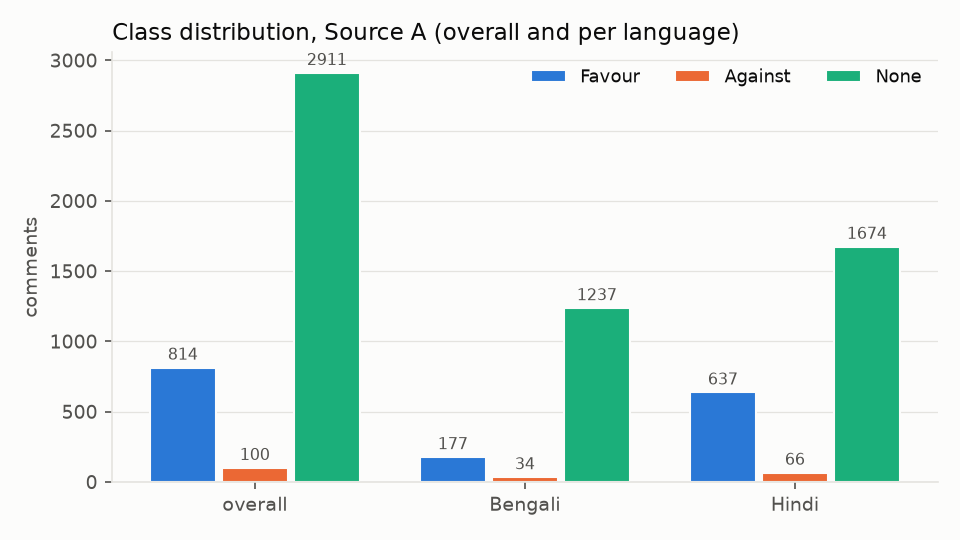

ds_class_split.png


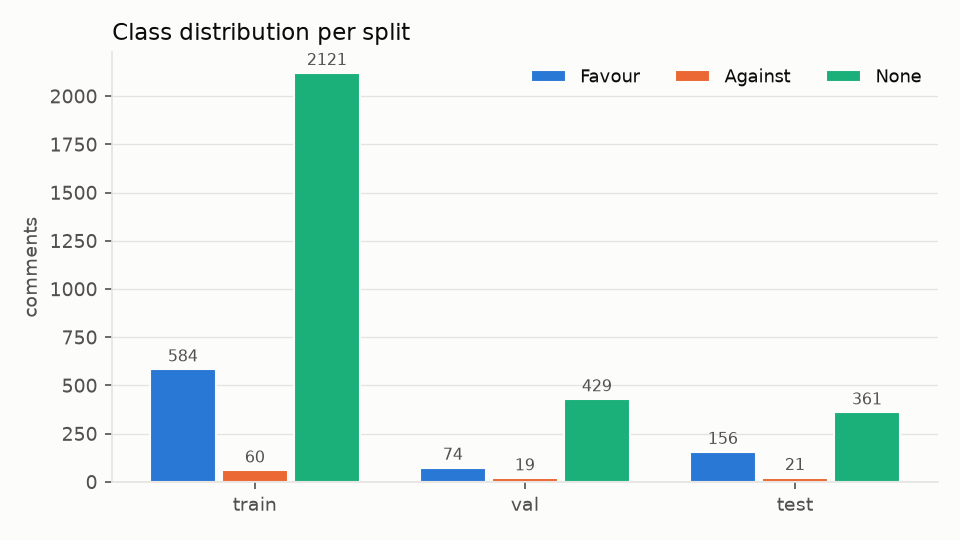

ds_length.png


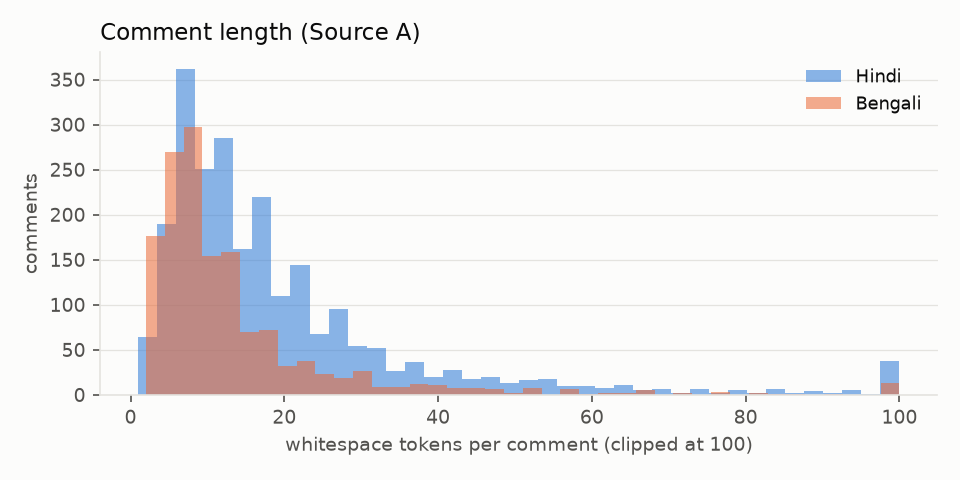

ds_script_mix.png


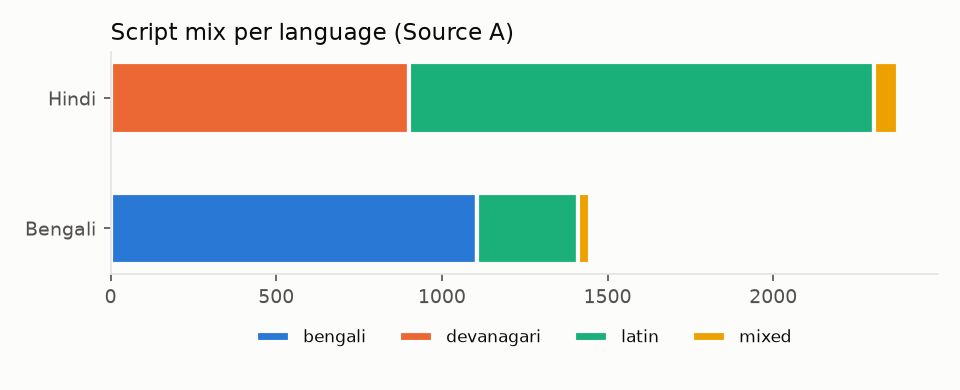

ds_sources.png


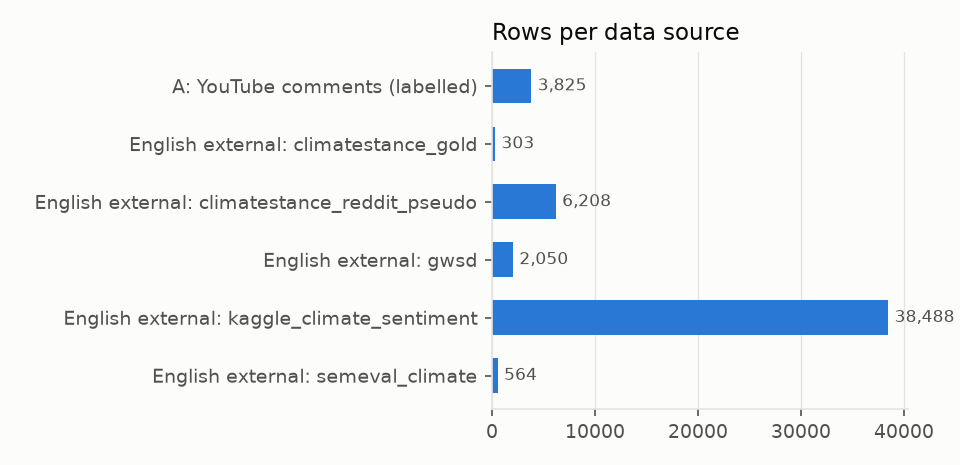

In [5]:
from IPython.display import Image
for f in sorted((ROOT / 'reports' / 'figures').glob('ds_*.png')):
    print(f.name); display(Image(filename=str(f)))